**Dataset Selection**

In [1]:
# Step 1: Install the UCI dataset library
!pip -q install ucimlrepo

In [2]:

# Step 1.3: Download the official UCI Air Quality dataset

import urllib.request
import zipfile
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

# Download the ZIP file
response = urllib.request.urlopen(url)
zip_bytes = response.read()

# Open ZIP file in memory
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
    # Find the original CSV file
    csv_file = next(
        name for name in z.namelist()
        if name.lower().endswith("airqualityuci.csv")
    )

    # Read semicolon-separated data with decimal commas
    with z.open(csv_file) as file:
        df = pd.read_csv(
            file,
            sep=";",
            decimal=",",
            encoding="utf-8-sig"
        )

# Remove empty columns, if any
df = df.dropna(axis=1, how="all")

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset downloaded successfully!
Dataset shape: (9471, 15)

First 5 rows:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [3]:

# Display column names
print("Column names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Check the number of rows and columns
print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

# Statistical summary
print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,03/04/2005,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


In [4]:

# Check assignment requirement: minimum 15 fields

print("Number of features/fields:", len(df.columns))

if len(df.columns) >= 15:
    print("PASS: Dataset meets the minimum 15-field requirement.")
else:
    print("WARNING: Check the loaded dataset columns.")

# Check missing-value markers used by UCI
print("\nNumber of -200 values in each column:")
print((df == -200).sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Number of features/fields: 15
PASS: Dataset meets the minimum 15-field requirement.

Number of -200 values in each column:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

Duplicate rows: 113


**Data Understanding & Preprocessing**

In [5]:
# Display the first 5 rows
display(df.head())

# Display the last 5 rows
display(df.tail())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dataset shape: (9471, 15)

Columns:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [6]:
import numpy as np
import pandas as pd

# Replace invalid missing-value markers
df = df.replace(-200, np.nan)

# Count missing values in each column
missing = df.isnull().sum()

print("Missing values in each column:")
display(missing[missing > 0].sort_values(ascending=False))

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing percentage:")
display(missing_percentage[missing_percentage > 0].round(2))

Missing values in each column:


,0
NMHC(GT),8557
CO(GT),1797
NO2(GT),1756
NOx(GT),1753
PT08.S2(NMHC),480
C6H6(GT),480
PT08.S1(CO),480
PT08.S5(O3),480
T,480
PT08.S3(NOx),480



Missing percentage:


,0
Date,1.20
Time,1.20
CO(GT),18.97
PT08.S1(CO),5.07
NMHC(GT),90.35
C6H6(GT),5.07
PT08.S2(NMHC),5.07
NOx(GT),18.51
PT08.S3(NOx),5.07
NO2(GT),18.54


In [7]:
# Convert Date and Time into a datetime column
if "Date" in df.columns and "Time" in df.columns:
    df["DateTime"] = pd.to_datetime(
        df["Date"].astype(str) + " " + df["Time"].astype(str),
        dayfirst=True,
        errors="coerce"
    )

    print("DateTime conversion completed.")
    display(df[["Date", "Time", "DateTime"]].head())
else:
    print("Date or Time column not found. Check column names.")

/tmp/ipykernel_780/398489249.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["DateTime"] = pd.to_datetime(


DateTime conversion completed.


,Date,Time,DateTime
0,10/03/2004,18.00.00,NaT
1,10/03/2004,19.00.00,NaT
2,10/03/2004,20.00.00,NaT
3,10/03/2004,21.00.00,NaT
4,10/03/2004,22.00.00,NaT


In [8]:
# Count duplicate records
print("Duplicate rows before removal:", df.duplicated().sum())

# Remove exact duplicate records
df = df.drop_duplicates().copy()

print("Dataset shape after duplicate removal:", df.shape)

Duplicate rows before removal: 113
Dataset shape after duplicate removal: (9358, 16)


In [9]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Interpolate missing numeric measurements
df[numeric_cols] = df[numeric_cols].interpolate(
    method="linear",
    limit_direction="both"
)

# Check remaining missing values
print("Remaining missing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Remaining missing values:


,0
Date,1
Time,1
DateTime,9358


In [10]:
target = "CO(GT)"

if target in df.columns:
    print("Target column found:", target)
    print("Missing target values:", df[target].isna().sum())
    print("Target statistics:")
    display(df[target].describe())
else:
    print("Target column not found.")
    print("Available columns:", df.columns.tolist())

Target column found: CO(GT)
Missing target values: 0
Target statistics:


,CO(GT)
count,9358.00000
mean,2.13061
std,1.43166
min,0.10000
25%,1.10000
50%,1.80000
75%,2.90000
max,11.90000


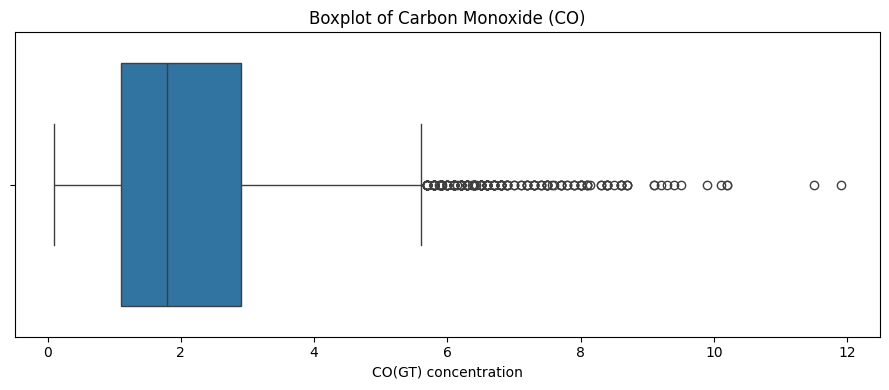

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

if target in df.columns:
    plt.figure(figsize=(9, 4))
    sns.boxplot(x=df[target].dropna())
    plt.title("Boxplot of Carbon Monoxide (CO)")
    plt.xlabel("CO(GT) concentration")
    plt.tight_layout()
    plt.show()

**Data Visualization**

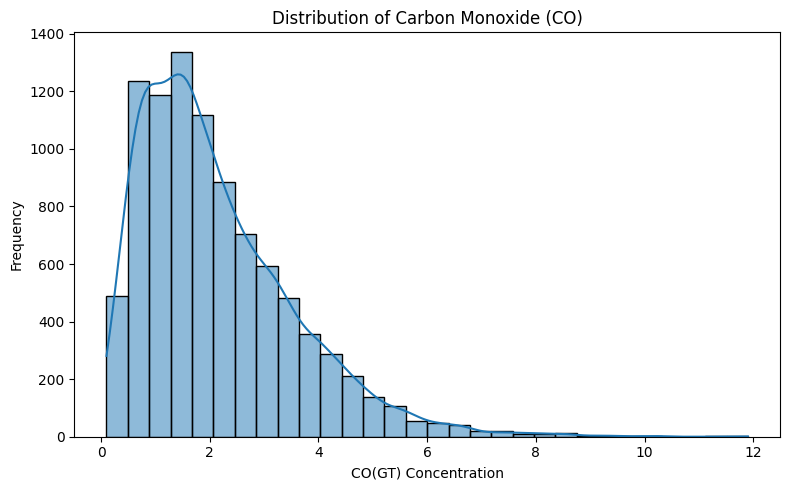

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df["CO(GT)"].dropna(), bins=30, kde=True)

plt.title("Distribution of Carbon Monoxide (CO)")
plt.xlabel("CO(GT) Concentration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

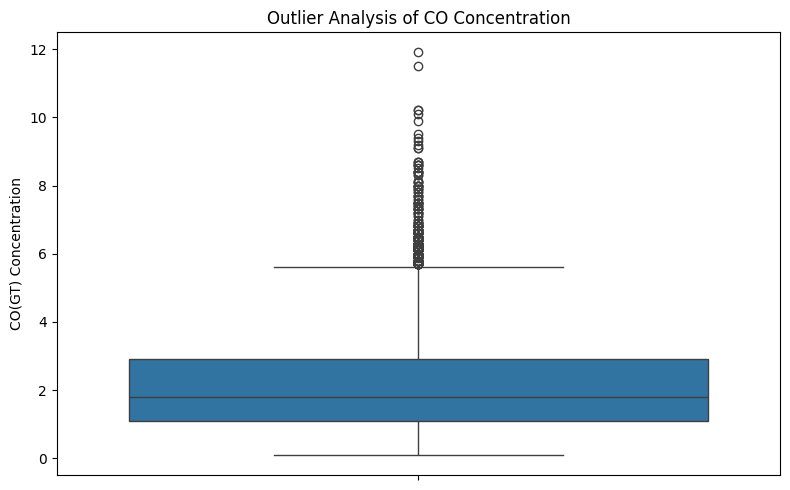

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["CO(GT)"].dropna())

plt.title("Outlier Analysis of CO Concentration")
plt.ylabel("CO(GT) Concentration")
plt.tight_layout()
plt.show()

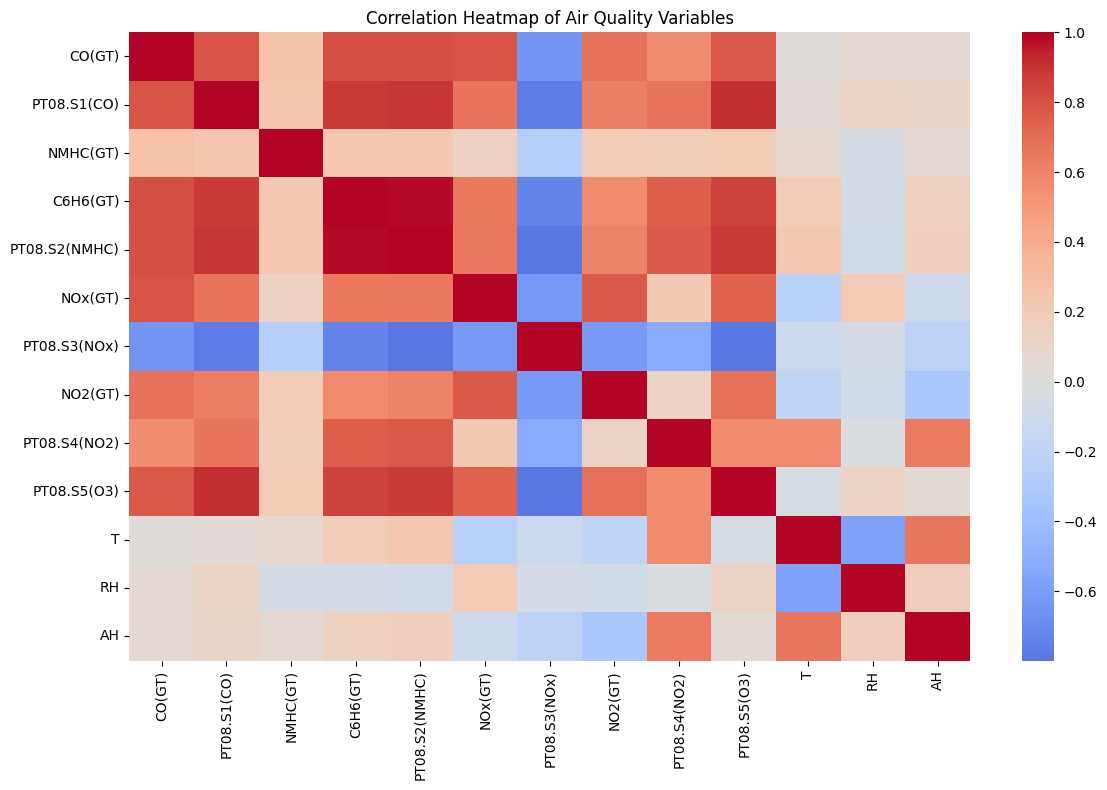

In [14]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Air Quality Variables")
plt.tight_layout()
plt.show()

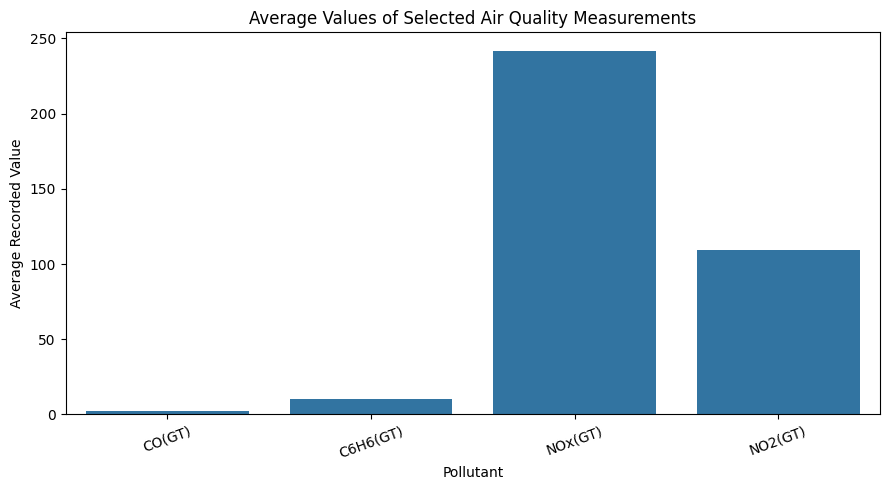

In [15]:
pollutants = [
    col for col in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
    if col in df.columns
]

pollutant_means = df[pollutants].mean().dropna()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=pollutant_means.index,
    y=pollutant_means.values
)

plt.title("Average Values of Selected Air Quality Measurements")
plt.xlabel("Pollutant")
plt.ylabel("Average Recorded Value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

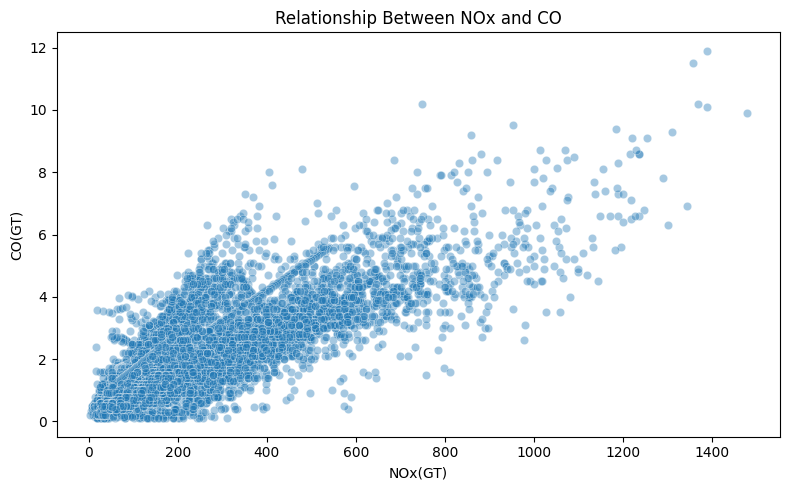

In [16]:
if "CO(GT)" in df.columns and "NOx(GT)" in df.columns:
    plot_df = df[["CO(GT)", "NOx(GT)"]].dropna()

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=plot_df,
        x="NOx(GT)",
        y="CO(GT)",
        alpha=0.4
    )

    plt.title("Relationship Between NOx and CO")
    plt.xlabel("NOx(GT)")
    plt.ylabel("CO(GT)")
    plt.tight_layout()
    plt.show()

In [18]:
# Recreate DateTime column correctly
df["DateTime"] = pd.to_datetime(
    df["Date"].astype(str).str.strip() + " " +
    df["Time"].astype(str).str.strip(),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

print("Valid DateTime values:", df["DateTime"].notna().sum())
print("Total rows:", len(df))
display(df[["Date", "Time", "DateTime"]].head())

Valid DateTime values: 9357
Total rows: 9358


,Date,Time,DateTime
0,10/03/2004,18.00.00,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2004-03-10 21:00:00
4,10/03/2004,22.00.00,2004-03-10 22:00:00


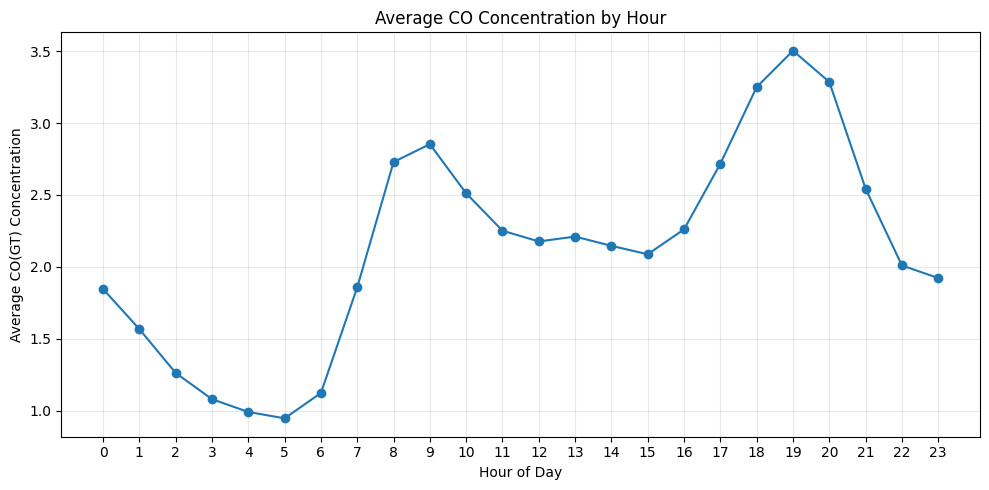

Hours available in graph: 24


In [19]:
# Keep valid DateTime and CO values
time_df = df[["DateTime", "CO(GT)"]].dropna().copy()

# Extract hour from DateTime
time_df["Hour"] = time_df["DateTime"].dt.hour

# Calculate average CO for each hour
hourly_co = time_df.groupby("Hour")["CO(GT)"].mean()

# Plot graph
plt.figure(figsize=(10, 5))
plt.plot(hourly_co.index, hourly_co.values, marker="o")

plt.title("Average CO Concentration by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average CO(GT) Concentration")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Hours available in graph:", len(hourly_co))

**Deep Learning Model Building**

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Sort dataset chronologically
df = df.sort_values("DateTime").reset_index(drop=True)

# Target column
target = "CO(GT)"

# Select numeric input features
exclude_cols = [target]
feature_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in exclude_cols
]

# Create feature matrix and target
X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df[target]

# Remove rows where target is missing
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Features:", feature_cols)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Features: ['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Input shape: (9358, 12)
Target shape: (9358,)


In [21]:
# 70% training, 15% validation, 15% testing
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 6550
Validation samples: 1404
Testing samples: 1404


In [22]:
# Handle missing feature values
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

# Standardize numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Preprocessing completed!")
print("Training input:", X_train_scaled.shape)
print("Validation input:", X_val_scaled.shape)
print("Testing input:", X_test_scaled.shape)

Preprocessing completed!
Training input: (6550, 12)
Validation input: (1404, 12)
Testing input: (1404, 12)


In [23]:
# Fix random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Build the MLP regression model
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train.to_numpy(),
    validation_data=(X_val_scaled, y_val.to_numpy()),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0980 - mae: 0.7195 - val_loss: 1.0582 - val_mae: 0.7662
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3542 - mae: 0.4046 - val_loss: 0.6869 - val_mae: 0.5694
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2861 - mae: 0.3594 - val_loss: 0.6091 - val_mae: 0.5383
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2646 - mae: 0.3455 - val_loss: 0.6089 - val_mae: 0.5438
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2527 - mae: 0.3386 - val_loss: 0.6173 - val_mae: 0.5499
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2449 - mae: 0.3337 - val_loss: 0.6204 - val_mae: 0.5513
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2387 - mae: 0.3303 - val_loss: 0.6281 - val_mae: 0.5553
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2332 - mae: 0.3272 - val_loss: 0.6309 - val_mae: 0.5563
Epoch 9/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - lo

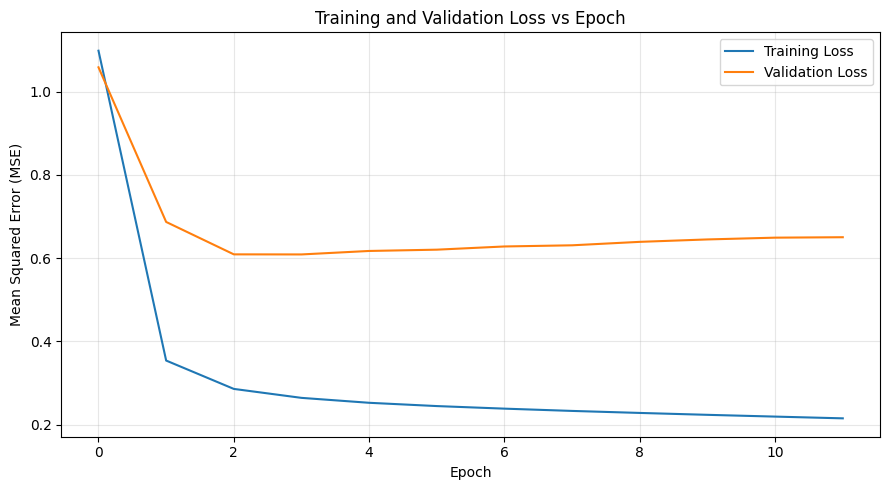

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

MAE  : 0.4542
RMSE : 0.6097
R²   : 0.7861


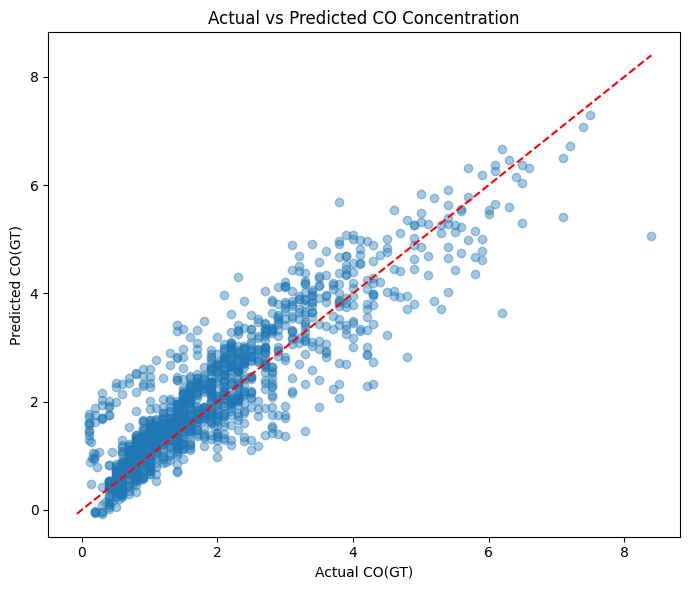

In [26]:
# Predict using unseen test data
y_pred = model.predict(X_test_scaled, verbose=0).ravel()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# Plot actual vs predicted values
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.title("Actual vs Predicted CO Concentration")
plt.xlabel("Actual CO(GT)")
plt.ylabel("Predicted CO(GT)")
plt.tight_layout()
plt.show()

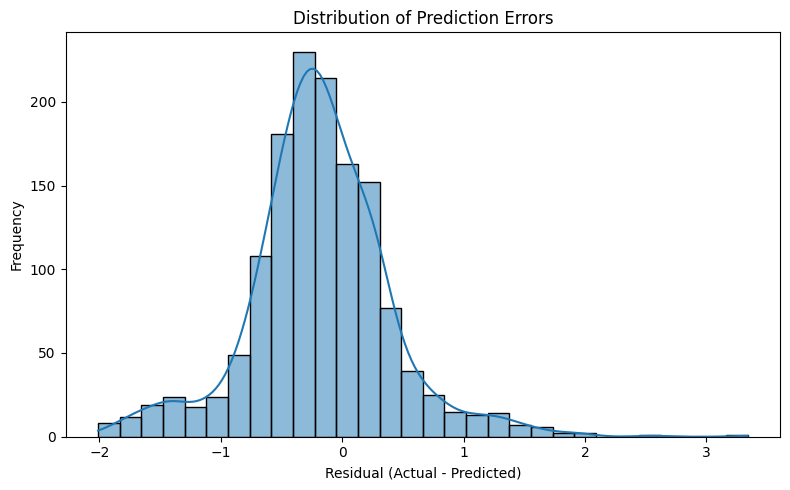

In [27]:
residuals = np.asarray(y_test) - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

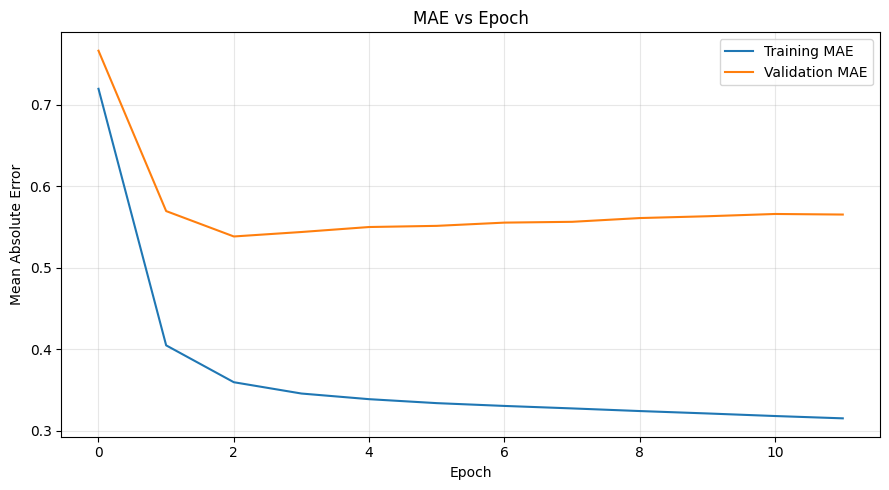

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("MAE vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on test data
perm_result = permutation_importance(
    model,
    X_test_scaled,
    y_test.to_numpy(),
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42
)

# Create a feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": perm_result.importances_mean
}).sort_values(by="Importance", ascending=False)

print("Top 10 important features:")
display(importance_df.head(10))

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 963us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 979us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 994us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 920us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 941us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 976us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 991us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 916us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 935us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step
44/44 ━━━━━━━━━━━━━━

,Feature,Importance
4,NOx(GT),0.302521
7,PT08.S4(NO2),0.226261
6,NO2(GT),0.223465
8,PT08.S5(O3),0.172032
2,C6H6(GT),0.110904
0,PT08.S1(CO),0.107758
3,PT08.S2(NMHC),0.104771
11,AH,0.073946
5,PT08.S3(NOx),0.060079
10,RH,0.002994


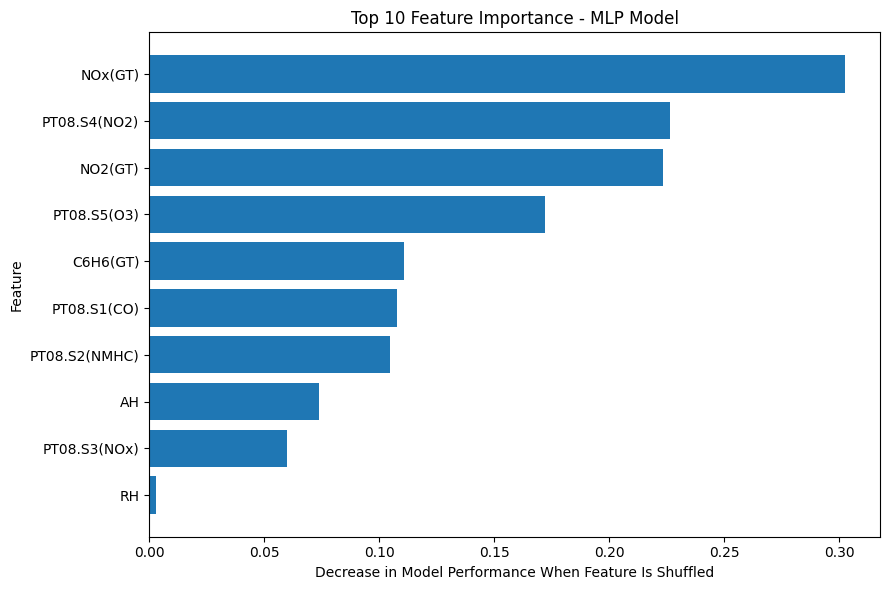

In [30]:
top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importance - MLP Model")
plt.xlabel("Decrease in Model Performance When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [31]:
# Compare different MLP architectures
architectures = {
    "MLP_32_16": [32, 16],
    "MLP_64_32": [64, 32],
    "MLP_128_64": [128, 64]
}

tuning_results = []

for name, units in architectures.items():

    tf.keras.utils.set_random_seed(42)

    tuned_model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(units[0], activation="relu"),
        layers.Dense(units[1], activation="relu"),
        layers.Dense(1)
    ])

    tuned_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    tuned_model.fit(
        X_train_scaled,
        y_train.to_numpy(),
        validation_data=(X_val_scaled, y_val.to_numpy()),
        epochs=30,
        batch_size=32,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    val_loss, val_mae = tuned_model.evaluate(
        X_val_scaled,
        y_val.to_numpy(),
        verbose=0
    )

    tuning_results.append({
        "Architecture": name,
        "Validation_MSE": val_loss,
        "Validation_MAE": val_mae
    })

tuning_df = pd.DataFrame(tuning_results).sort_values(
    by="Validation_MAE"
)

display(tuning_df)

,Architecture,Validation_MSE,Validation_MAE
2,MLP_128_64,0.593215,0.525436
1,MLP_64_32,0.608918,0.543756
0,MLP_32_16,0.658302,0.569338


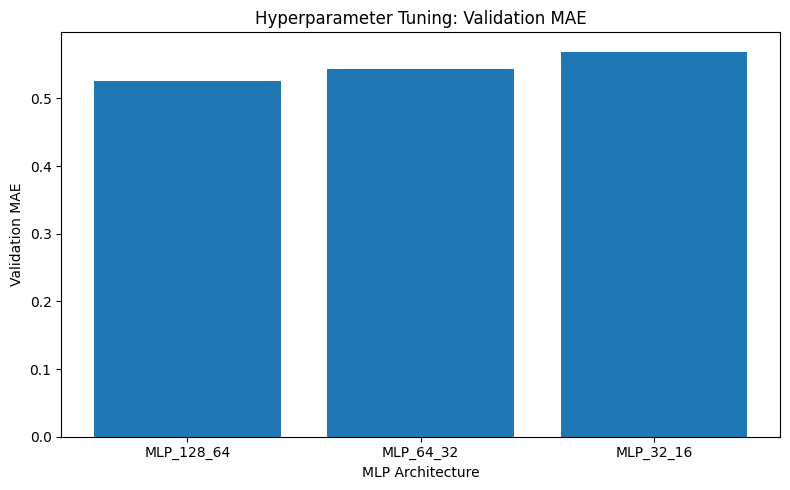

Best architecture based on validation MAE: MLP_128_64


In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    tuning_df["Architecture"],
    tuning_df["Validation_MAE"]
)

plt.title("Hyperparameter Tuning: Validation MAE")
plt.xlabel("MLP Architecture")
plt.ylabel("Validation MAE")
plt.tight_layout()
plt.show()

best_architecture = tuning_df.iloc[0]["Architecture"]

print("Best architecture based on validation MAE:",
      best_architecture)